In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers


# a. Loading and preprocessing the image data

# Load Sign Language MNIST CSV files
train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

Training data: (27455, 785)
Testing data: (7172, 785)


In [2]:
train_data.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [10]:
x_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

x_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

x_train = x_train.reshape(-1, 28,28,1)
x_test = x_test.reshape(-1, 28,28,1)

x_train = x_train/255.0
x_test = x_test/255.0

model = keras.Sequential([
    layers.Input(shape=(28,28,1)),
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(25, activation='softmax')
])

model.summary()

model.compile(
    optimizer='adam',
    loss = "sparse_categorical_crossentropy",
    metrics = ['accuracy']
)

history = model.fit(x_train, y_train, epochs=10, batch_size=64, validation_split=0.2)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 25)                  │           3,225 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 226,969 (886.60 KB)

 Trainable params: 226,969 (886.60 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 25s 59ms/step - accuracy: 0.5913 - loss: 1.3885 - val_accuracy: 0.8829 - val_loss: 0.3948
Epoch 2/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 33s 50ms/step - accuracy: 0.9440 - loss: 0.2030 - val_accuracy: 0.9854 - val_loss: 0.0841
Epoch 3/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - accuracy: 0.9948 - loss: 0.0436 - val_accuracy: 0.9975 - val_loss: 0.0264
Epoch 4/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - accuracy: 0.9995 - loss: 0.0130 - val_accuracy: 0.9996 - val_loss: 0.0101
Epoch 5/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 1.0000 - loss: 0.0052 - val_accuracy: 0.9998 - val_loss: 0.0052
Epoch 6/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 1.0000 - loss: 0.0028 - val_accuracy: 1.0000 - val_loss: 0.0032
Epoch 7/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 1.0000 - val_loss: 0.0020
Epoch 8/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step - accuracy: 1.0000 - loss: 0.0012 - 

225/225 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.8957 - loss: 0.4087
Test Loss: 0.4086693525314331
Test Accuracy: 0.89570552110672


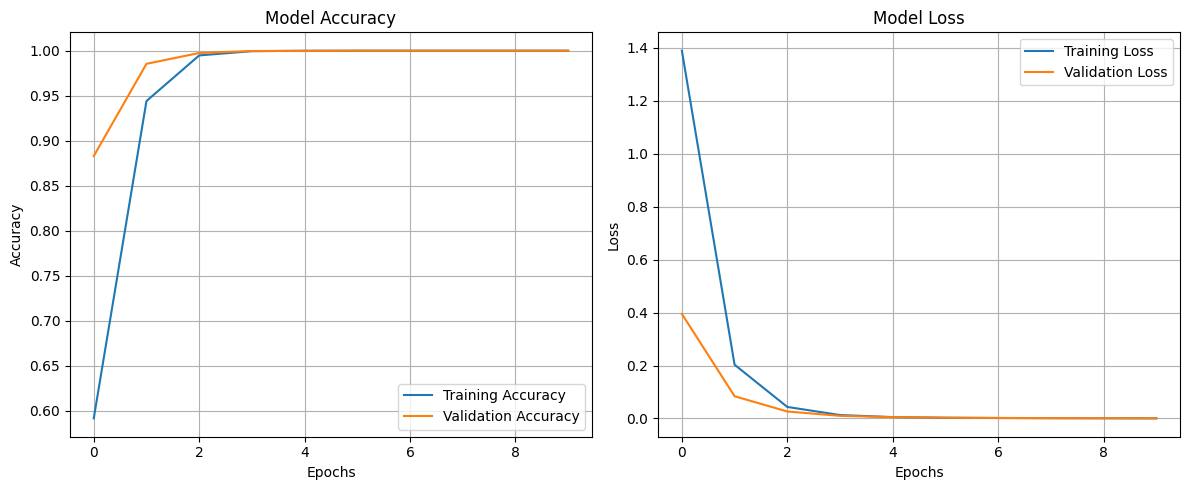

In [11]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()